# Experiment 6: training-corpus eligibility — results

Compare all PD training tables with those above 10,000 rows. The episode cap is 8,192 in both arms. This policy changes table diversity and revisit frequency; small tables may supply fewer rows.

Does a large-table-only credit training policy improve transfer while evaluation tables stay fixed? Table composition, diversity and revisit frequency change together.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, size_studies as ss
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment6/02_results')
report = cp.NotebookReport('Experiment 6: training-corpus eligibility — results', sink=sink)
print(source_description())
arms = ss.load_arms(6)
report.add('0. Evidence and scope', source_description() + '\n' + 'Compare all PD training tables with those above 10,000 rows. The episode cap is 8,192 in both arms. This policy changes table diversity and revisit frequency; small tables may supply fewer rows.')
from src.visualize import prediction_diagnostics as pred


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Coverage and the fixed evaluation population

In [2]:
report.table('Planned and recorded evidence', ss.coverage(arms))
report.table('Prepared corpus and exposure inventory', ss.corpus_inventory(arms))
report.add('1. Coverage and the fixed evaluation population', 'Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.')

,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,All tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155
1,Large tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155


,arm,partition,id,available_rows,episode_rows,query_rows,visit_share,held_out_tables
0,All tables,0,0001.gmsc,150000,8192,3277,0.076923,4
1,All tables,0,0002.taiwan_creditcard,30000,8192,3277,0.076923,4
2,All tables,0,0003.vehicle_loan,233154,8192,3277,0.076923,4
3,All tables,0,0004.lendingclub,9578,8192,3277,0.076923,4
4,All tables,0,0005.myhom,7000,7000,2800,0.076923,4
...,...,...,...,...,...,...,...,...
79,Large tables,3,PropPD1,100000,8192,3277,0.111111,4
80,Large tables,3,PropPD2,105471,8192,3277,0.111111,4
81,Large tables,3,0014.algorithmwatch,158700,8192,3277,0.111111,4
82,Large tables,3,0015.credit_risk_dataset,32581,8192,3277,0.111111,4


## 2. Paired AUC effects and study contrasts

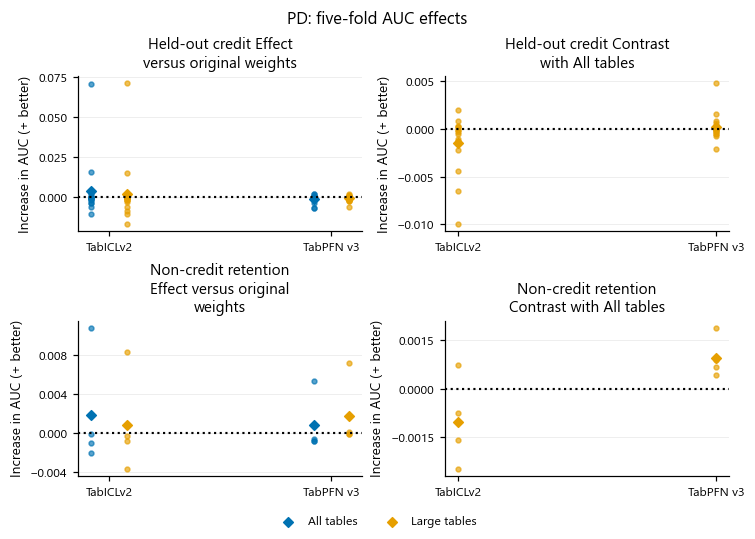

Points are table-level paired effects and diamonds are equal-table means. Five finite outer folds are required for both CPT and its original-weight control, and every displayed arm must be present for the same table. Non-credit effects first average the four matched training partitions. Right panels subtract the All tables effect within table. Positive values indicate improvement; points are not independent across related data sources. The 8,192-row large-table checkpoint is shared across experiments 6 and 7, not an independent replication.

In [3]:
cp.show(sink, ss.plot_benchmark(arms))
report.add('2. Paired AUC effects and study contrasts', 'Report all prescribed arms. Each table is paired across arms and its original-weight control, requiring complete five-fold evaluation. Partitions and CV folds are not independent replications.')

## 3. Probability quality

Saved raw test predictions additionally measure systematic over/underprediction and paired prediction changes. These diagnostics describe observed errors; they do not identify theoretical bias or context variance.


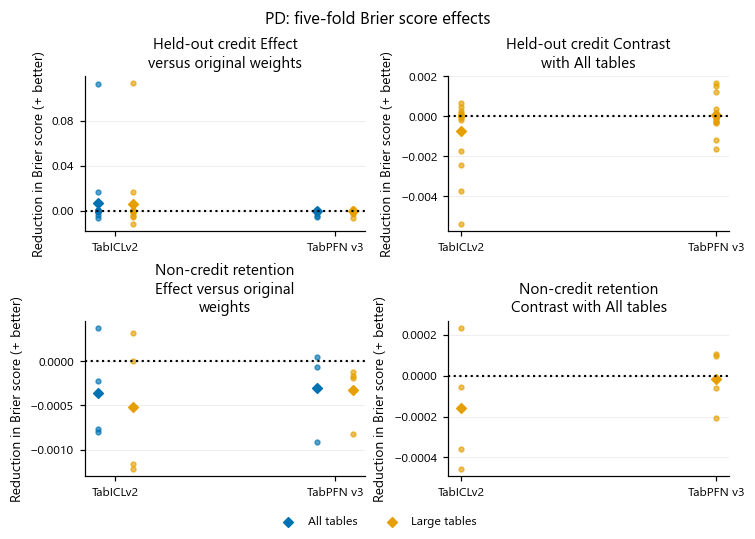

Points are table-level paired effects and diamonds are equal-table means. Five finite outer folds are required for both CPT and its original-weight control, and every displayed arm must be present for the same table. Non-credit effects first average the four matched training partitions. Right panels subtract the All tables effect within table. Positive values indicate improvement; points are not independent across related data sources. The 8,192-row large-table checkpoint is shared across experiments 6 and 7, not an independent replication.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,All tables,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,All tables,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,All tables,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,All tables,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,All tables,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,All tables,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,All tables,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,All tables,verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,All tables,verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,All tables,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,All tables,730176,0.138105,0.135123,0.133391,-0.002982,-0.004714,-0.001732,0.080536,0.080793,-0.000258,-0.001732,0.021814,0.010710
1,TabICLv2,HMEQ,0,All tables,5960,0.199497,0.190717,0.189300,-0.008779,-0.010197,-0.001417,0.017686,0.018719,-0.001032,-0.001417,0.033627,0.011054
2,TabICLv2,MicroFinance,0,All tables,158700,0.378091,0.364956,0.364817,-0.013134,-0.013273,-0.000139,0.218164,0.218839,-0.000675,-0.000139,0.031016,0.023326
3,TabICLv2,Thomas,0,All tables,1225,0.263673,0.247090,0.241769,-0.016584,-0.021905,-0.005321,0.183083,0.183631,-0.000549,-0.005321,0.015753,0.010984
4,TabICLv2,GMSC,1,All tables,150000,0.066840,0.057865,0.056884,-0.008975,-0.009956,-0.000981,0.049076,0.049168,-0.000092,-0.000981,0.006900,0.003364
5,TabICLv2,German Credit,1,All tables,999,0.300300,0.292743,0.289586,-0.007557,-0.010714,-0.003157,0.162400,0.161775,0.000625,-0.003157,0.027575,0.019273
6,TabICLv2,Taiwan Credit Card,1,All tables,30000,0.221200,0.206801,0.204757,-0.014399,-0.016443,-0.002044,0.132926,0.133325,-0.000400,-0.002044,0.017322,0.012554
7,TabICLv2,Vehicle Loan,1,All tables,233154,0.217071,0.387294,0.193619,0.170223,-0.023452,0.146772,0.274762,0.161953,0.112809,-0.193675,0.349919,0.217064
8,TabICLv2,Credit Risk,2,All tables,32581,0.218164,0.207034,0.208866,-0.011130,-0.009298,0.001831,0.049365,0.053493,-0.004128,0.001831,0.052628,0.024476
9,TabICLv2,Hackerearth,2,All tables,532428,0.236327,0.231125,0.228143,-0.005201,-0.008184,-0.002982,0.058127,0.064752,-0.006625,-0.002982,0.072725,0.032864


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Large tables,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Large tables,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Large tables,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Large tables,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Large tables,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,Large tables,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,Large tables,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,Large tables,verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,Large tables,verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,Large tables,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Large tables,730176,0.138105,0.135123,0.133006,-0.002982,-0.005099,-0.002117,0.080536,0.080545,-0.000010,-0.002117,0.019760,0.009311
1,TabICLv2,HMEQ,0,Large tables,5960,0.199497,0.190717,0.193290,-0.008779,-0.006207,0.002573,0.017686,0.022467,-0.004781,0.002573,0.048580,0.018183
2,TabICLv2,MicroFinance,0,Large tables,158700,0.378091,0.364956,0.368367,-0.013134,-0.009724,0.003411,0.218164,0.218378,-0.000214,0.003411,0.030211,0.022704
3,TabICLv2,Thomas,0,Large tables,1225,0.263673,0.247090,0.242592,-0.016584,-0.021081,-0.004498,0.183083,0.183812,-0.000729,-0.004498,0.022282,0.014948
4,TabICLv2,GMSC,1,Large tables,150000,0.066840,0.057865,0.057640,-0.008975,-0.009200,-0.000225,0.049076,0.049151,-0.000075,-0.000225,0.006955,0.003296
5,TabICLv2,German Credit,1,Large tables,999,0.300300,0.292743,0.289789,-0.007557,-0.010512,-0.002955,0.162400,0.162447,-0.000047,-0.002955,0.028202,0.019911
6,TabICLv2,Taiwan Credit Card,1,Large tables,30000,0.221200,0.206801,0.206487,-0.014399,-0.014713,-0.000314,0.132926,0.133250,-0.000324,-0.000314,0.016720,0.011699
7,TabICLv2,Vehicle Loan,1,Large tables,233154,0.217071,0.387294,0.195776,0.170223,-0.021295,0.148929,0.274762,0.161803,0.112959,-0.191518,0.348573,0.215671
8,TabICLv2,Credit Risk,2,Large tables,32581,0.218164,0.207034,0.207001,-0.011130,-0.011163,-0.000034,0.049365,0.055204,-0.005840,-0.000034,0.059807,0.028837
9,TabICLv2,Hackerearth,2,Large tables,532428,0.236327,0.231125,0.219707,-0.005201,-0.016619,-0.011418,0.058127,0.070155,-0.012027,-0.011418,0.102699,0.049356


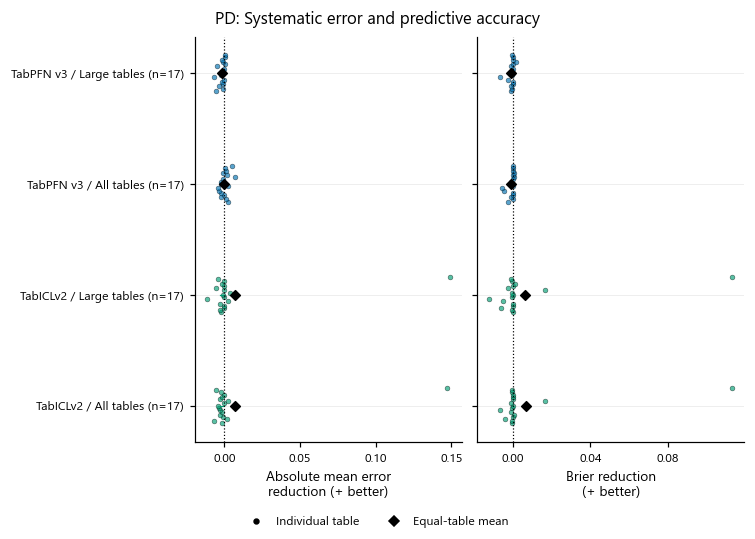

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [4]:
cp.show(sink, ss.plot_benchmark(arms, 'brier_score'))
prediction_tables, coverage_tables = [], []
for arm, run in arms.items():
    values, coverage = pred.analyze(run, arm=arm)
    prediction_tables.append(values)
    coverage_tables.append(coverage)
    report.table(arm+' saved prediction coverage', coverage)
    report.table(arm+' paired per-table prediction diagnostics', values)
cp.show(sink, pred.plot_arms(prediction_tables, coverage_tables, 'pd'), track='pd')
report.add('3. Probability quality', 'Positive Brier effects mean a reduction in error. These are secondary outcomes at natural test prevalence; do not select an arm with them.' + '\n' + pred.NOTE)


## 4. Interpretation

In [5]:
report.table('Completed and unavailable comparisons', ss.coverage(arms))
report.add('4. Interpretation', 'Compare all PD training tables with those above 10,000 rows. The episode cap is 8,192 in both arms. This policy changes table diversity and revisit frequency; small tables may supply fewer rows. Differences are descriptive for this credit corpus, horizon and two base architectures. These studies do not estimate a corpus-by-episode interaction or an effect of dataset size independent of population identity.')

,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,All tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155
1,Large tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155


## Complete text summary

In [6]:
print(report.summary(sink))

Experiment 6: training-corpus eligibility — results

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Compare all PD training tables with those above 10,000 rows. The episode cap is 8,192 in both arms. This policy changes table diversity and revisit frequency; small tables may supply fewer rows.

1. Coverage and the fixed evaluation population
Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.

Table: Planned and recorded evidence
CSV (first column: row index)
row,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,All tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155
1,Large tables,experiment6,cpt_corpus_v1,8,8,0,0,48,1155

Table: Prepared corpus a